# 02. Climate Drivers: ONI and DMI

CRISP-DM phase: Data understanding + Evaluation

This notebook looks at the two ocean climate indices in the model, the Oceanic Nino Index (`oni`, El Nino and La Nina in the Pacific) and the Dipole Mode Index (`dmi`, the Indian Ocean Dipole). It asks three questions:

1. Are floods in Kenya more common in some climate phases than in others, and in which rainy season?
2. Did the pattern found in the training years (2002 to 2019) hold in the test years (2020 to 2024)?
3. Do the models actually use the two indices, and does a season-specific version of them help?

The patterns are found on the training rows only. The test rows are used once, in Section 5, to check whether the pattern held. Like the other notebooks, this one prints only counts and rates, never rows or events from the flood records.

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

### 1.2 Loading the Training and Test Sets

In [2]:
#loading the saved training and test sets (pcode as text)
train = pd.read_csv('../data/train.csv', dtype={'pcode': str})
test = pd.read_csv('../data/test.csv', dtype={'pcode': str})
print(train.shape, test.shape)

(9870, 30) (2820, 30)


## 2. The Two Indices

### 2.1 One Value per Month

`oni` and `dmi` describe the ocean, not the county, so every county has the same value in a given month. The next cells check this and keep one row per month.

In [3]:
#number of different oni and dmi values within each month (should print 1 and 1)
print(train.groupby(['year', 'month'])['oni'].nunique().max())
print(train.groupby(['year', 'month'])['dmi'].nunique().max())

1
1


In [4]:
#one row per month in the training years
months = train.groupby(['year', 'month'])[['oni', 'dmi']].first().reset_index()
months[['oni', 'dmi']].describe().round(2)

,oni,dmi
count,210.00,210.00
mean,0.08,0.03
std,0.82,0.35
min,-1.64,-0.89
25%,-0.46,-0.19
50%,0.09,0.01
75%,0.58,0.24
max,2.75,1.17


In [5]:
#how strongly the two indices move together, month by month
print(round(months['oni'].corr(months['dmi']), 2))

0.16


#### Observation

Every county has the same `oni` and `dmi` in a given month (both checks print 1), so the training set holds 210 different values of each, one per month. ONI ranges from -1.64 to 2.75 (the top value is the strong 2015 to 2016 El Nino) and DMI from -0.89 to 1.17. The two indices are only weakly related (correlation 0.16), so they carry mostly separate information and it makes sense to keep both in the analysis.

### 2.2 Climate Phases

Each month is given a phase with the usual thresholds:

- **ENSO** (from `oni`): El Nino when ONI is 0.5 or more, La Nina when it is -0.5 or less, and neutral in between (NOAA thresholds).
- **IOD** (from `dmi`): positive when DMI is 0.4 or more, negative when it is -0.4 or less, and neutral in between (Australian Bureau of Meteorology thresholds).

The official definitions also ask for the value to last several months. Here each month is classified on its own value, which is simpler and good enough for a comparison of flood rates.

In [6]:
#adding the ENSO and IOD phase of each month
def add_phases(df):
    df = df.copy()
    df['enso'] = pd.cut(df['oni'], [-np.inf, -0.5, 0.5, np.inf], right=False, labels=['La Nina', 'neutral', 'El Nino'])
    df['iod'] = pd.cut(df['dmi'], [-np.inf, -0.4, 0.4, np.inf], right=False, labels=['negative', 'neutral', 'positive'])
    return df

train = add_phases(train)
test = add_phases(test)
months = add_phases(months)

In [7]:
#number of training months in each phase
print(months['enso'].value_counts().reindex(['La Nina', 'neutral', 'El Nino']))
print(months['iod'].value_counts().reindex(['negative', 'neutral', 'positive']))

enso
La Nina     49
neutral    102
El Nino     59
Name: count, dtype: int64
iod
negative     22
neutral     154
positive     34
Name: count, dtype: int64


#### Observation

Of the 210 training months, 59 are El Nino, 49 La Nina and 102 neutral. IOD events are rarer: 34 positive months, 22 negative and 154 neutral. Every month has 47 rows (one per county), so a phase with few months still has many rows, but those rows share the same few months and the same weather. The flood rates below for the IOD phases rest on a small number of seasons, and they should be read as patterns, not precise numbers.

## 3. Flood Rate by Season and Phase

### 3.1 The Rainy Season of the Flood Month

Each row describes this month and the target is a flood **next month**. Kenya has two rainy seasons: the long rains (March to May) and the short rains (October to December). So the season is set from the month of the flood, which is the row's month plus one:

- **Long rains:** rows from February, March and April (flood month March, April or May)
- **Short rains:** rows from September, October and November (flood month October, November or December)
- **Other months:** the remaining six months

In [8]:
#the rainy season of the flood month (next month)
def add_season(df):
    df = df.copy()
    df['season'] = 'other months'
    df.loc[df['month'].isin([2, 3, 4]), 'season'] = 'long rains (MAM)'
    df.loc[df['month'].isin([9, 10, 11]), 'season'] = 'short rains (OND)'
    return df

train = add_season(train)
test = add_season(test)
train.groupby('season')['flood_next_month'].agg(['size', 'sum', 'mean']).round(3)

,size,sum,mean
season,,,
long rains (MAM),2397,366,0.153
other months,4935,234,0.047
short rains (OND),2538,282,0.111


#### Observation

Floods are concentrated in the two rainy seasons. In the training years, 15.3% of the long rains rows (366 of 2,397) and 11.1% of the short rains rows (282 of 2,538) are followed by a flood, against 4.7% in the other six months (234 of 4,935). The two rainy seasons hold half of the rows but 73% of the floods (648 of 882).

### 3.2 Flood Rate by IOD Phase

In [9]:
#flood rate next month by season and IOD phase (training years)
iod_table = train.groupby(['season', 'iod'], observed=True)['flood_next_month'].agg(['size', 'sum', 'mean']).round(3)
iod_table

size  sum   mean
season            iod                       
long rains (MAM)  negative   282   29  0.103
                  neutral   1974  306  0.155
                  positive   141   31  0.220
other months      negative   423    3  0.007
                  neutral   3807  186  0.049
                  positive   705   45  0.064
short rains (OND) negative   329    5  0.015
                  neutral   1457  146  0.100
                  positive   752  131  0.174

#### Observation

The IOD makes a large difference in the short rains. With a negative IOD only 1.5% of the short rains rows are followed by a flood (5 of 329), with a neutral IOD 10.0%, and with a positive IOD 17.4% (131 of 752). So a positive IOD comes with a flood rate about 1.7 times the neutral rate and more than 10 times the negative rate. This matches the known climate link: a positive IOD warms the western Indian Ocean next to East Africa, which brings more rain in October to December. The long rains show the same direction (10.3%, 15.5% and 22.0%), but a positive IOD happens in only 3 training months of February to April (141 rows), so that result rests on very little evidence. Outside the rainy seasons the differences are small (0.7% to 6.4%).

### 3.3 Flood Rate by ENSO Phase

In [10]:
#flood rate next month by season and ENSO phase (training years)
enso_table = train.groupby(['season', 'enso'], observed=True)['flood_next_month'].agg(['size', 'sum', 'mean']).round(3)
enso_table

size  sum   mean
season            enso                     
long rains (MAM)  La Nina   799  109  0.136
                  neutral   799  139  0.174
                  El Nino   799  118  0.148
other months      La Nina   940   32  0.034
                  neutral  2820  132  0.047
                  El Nino  1175   70  0.060
short rains (OND) La Nina   564   94  0.167
                  neutral  1175   57  0.049
                  El Nino   799  131  0.164

#### Observation

ENSO gives a less clear picture. In the short rains, El Nino rows have a flood rate of 16.4% against 4.9% for neutral rows, which fits the usual link between El Nino and wet short rains. But La Nina rows have almost the same rate (16.7%), which does not fit, because La Nina usually brings dry short rains in East Africa. In the long rains the three phases are close (13.6% to 17.4%). Section 3.4 looks at the two indices together to see where the La Nina result comes from.

### 3.4 Both Indices Together in the Short Rains

In [11]:
#short rains only: flood rate for each combination of ENSO and IOD phase
short = train[train['season'] == 'short rains (OND)']
both = short.pivot_table(index='enso', columns='iod', values='flood_next_month', aggfunc='mean', observed=True)
counts = short.pivot_table(index='enso', columns='iod', values='flood_next_month', aggfunc='size', observed=True)
print(counts)
both.round(3)

iod      negative  neutral  positive
enso                                
La Nina     188.0    235.0     141.0
neutral     141.0    752.0     282.0
El Nino       NaN    470.0     329.0


iod,negative,neutral,positive
enso,,,
La Nina,0.021,0.221,0.270
neutral,0.007,0.043,0.085
El Nino,NaN,0.132,0.210


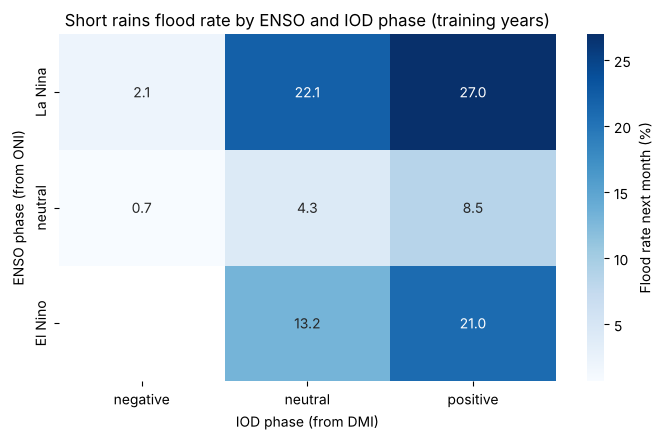

In [12]:
#heatmap of the short rains flood rate by ENSO and IOD phase
plt.figure(figsize=(7, 4.5))
sns.heatmap(both * 100, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': 'Flood rate next month (%)'})
plt.title('Short rains flood rate by ENSO and IOD phase (training years)')
plt.xlabel('IOD phase (from DMI)')
plt.ylabel('ENSO phase (from ONI)')
plt.tight_layout()
plt.show()

#### Observation

Within the short rains, the IOD separates the rows more cleanly than ENSO. With a negative IOD the flood rate is close to 0 whatever the ENSO phase (2.1% with La Nina and 0.7% when ENSO is neutral; there is no El Nino month with a negative IOD). The highest rates are with a positive IOD (21.0% with El Nino and 27.0% with La Nina). The high La Nina rates (22.1% with a neutral IOD and 27.0% with a positive IOD) come from only 8 months (376 rows), and 90 of their 91 floods are in just two seasons, 2007 and 2011, so they are not strong evidence that La Nina causes floods. A positive IOD is the common thread in the highest cells.

## 4. Year by Year: the Short Rains and the DMI

Section 3 pools all counties and months. This section asks the same question one year at a time: in years when the DMI was high in September to November, did more counties flood in October to December?

In [13]:
#short rains flood rate and mean oni and dmi of each training year
short_years = short.groupby('year').agg(flood_rate=('flood_next_month', 'mean'), dmi=('dmi', 'mean'), oni=('oni', 'mean'))
print(round(short_years['flood_rate'].corr(short_years['dmi']), 2))
print(round(short_years['flood_rate'].corr(short_years['oni']), 2))
short_years.sort_values('flood_rate', ascending=False).round(2).head(5)

0.34
0.25


,flood_rate,dmi,oni
year,,,
2015,0.47,0.39,2.20
2011,0.35,0.34,-0.78
2007,0.28,0.17,-1.07
2006,0.26,0.63,0.54
2009,0.23,-0.11,0.77


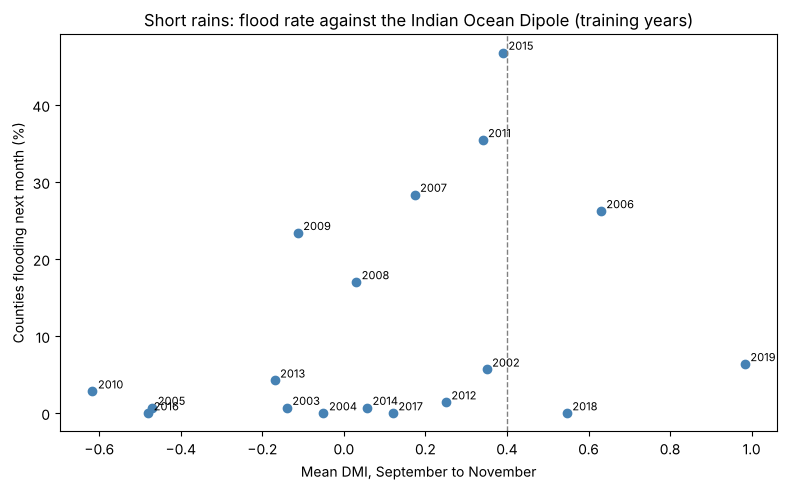

In [14]:
#scatter of the short rains flood rate against the mean dmi of september to november
plt.figure(figsize=(8, 5))
plt.scatter(short_years['dmi'], short_years['flood_rate'] * 100, color='steelblue')
for year, row in short_years.iterrows():
    plt.annotate(str(year), (row['dmi'], row['flood_rate'] * 100), fontsize=8, xytext=(4, 2), textcoords='offset points')
plt.axvline(0.4, color='grey', linestyle='--', linewidth=1)
plt.xlabel('Mean DMI, September to November')
plt.ylabel('Counties flooding next month (%)')
plt.title('Short rains: flood rate against the Indian Ocean Dipole (training years)')
plt.tight_layout()
plt.show()

#### Observation

Year by year, the short rains flood rate rises with the mean DMI of September to November (correlation 0.34), and a little less with the ONI (0.25). With 18 years these correlations are only moderate. The years with the most floods are 2015 (47% of counties, a very strong El Nino with a DMI close to the positive threshold), 2011 (35%), 2007 (28%) and 2006 (26%, a positive IOD year). Two positive IOD years sit far below the trend: 2018 (DMI 0.55, almost no labelled floods) and, most clearly, 2019, which has the highest DMI of all training years (0.98) but only 6% of the counties are labelled as flooded. Section 5.2 looks at this year again.

## 5. Did the Pattern Hold in the Test Years?

The pattern above was found on 2002 to 2019. The next cell repeats the IOD table on 2020 to 2024, which the models never trained on.

In [15]:
#flood rate next month by season and IOD phase (test years)
test.groupby(['season', 'iod'], observed=True)['flood_next_month'].agg(['size', 'sum', 'mean']).round(3)

size  sum   mean
season            iod                       
long rains (MAM)  neutral    564   91  0.161
                  positive   141   28  0.199
other months      negative    94    0  0.000
                  neutral    940    1  0.001
                  positive   376   13  0.035
short rains (OND) negative    47    0  0.000
                  neutral    517    2  0.004
                  positive   141    9  0.064

In [16]:
#short rains of each test year: flood rate and mean oni and dmi
test[test['season'] == 'short rains (OND)'].groupby('year').agg(flood_rate=('flood_next_month', 'mean'), dmi=('dmi', 'mean'), oni=('oni', 'mean')).round(2)

,flood_rate,dmi,oni
year,,,
2020,0.01,-0.01,-0.83
2021,0.01,0.01,-0.61
2022,0.00,-0.48,-0.93
2023,0.06,0.95,1.60
2024,0.00,-0.21,-0.15


#### Observation

In the test years the direction of the pattern holds: in the short rains the flood rate is highest with a positive IOD (6.4%, 9 of 141 rows), lower with a neutral IOD (0.4%, 2 of 517) and 0 with a negative IOD (0 of 47). But every short rains rate is much lower than in the training years (17.4%, 10.0% and 1.5%). The long rains look similar to the training years (16.1% with a neutral IOD and 19.9% with a positive one). The low short rains rates of 2020 to 2022 fit the climate of those years: the short rains failed during the 2020 to 2022 drought in the Horn of Africa, under La Nina and a neutral or negative IOD. The year that does not fit is 2023: it combines a strong positive IOD (0.95) with an El Nino (1.60), which in the training years came with the highest flood rates, yet only 6% of the counties are labelled as flooded.

### 5.2 A Label Check: Two Strong Positive IOD Years

The two years with the strongest positive IOD in the data are 2019 (mean DMI of 0.98 in September to November, the highest of all years) and 2023 (0.95, together with an El Nino). Both short rains seasons were widely reported as severe floods in Kenya:

- **2019:** UNICEF, quoting the National Disaster Operations Centre on 24 November 2019, reported 120 deaths from floods and landslides, at least 330,000 people affected and major roads cut off in 11 counties ([UNICEF Kenya Flood Situation Report 1](https://reliefweb.int/report/kenya/unicef-kenya-flood-situation-report-1-24-november-2019)).
- **2023:** the Kenya Red Cross reported 36 of the 47 counties affected by floods as of 24 November 2023 ([ECHO Daily Flash, 27 November 2023](https://reliefweb.int/report/kenya/kenya-floods-update-ifrc-media-kenya-meteorological-department-echo-daily-flash-27-november-2023)).

The next cell counts how many counties our labels mark as flooded in each of those months.

In [17]:
#number of counties labelled as flooded (flood_this_month) in october to december of 2019 and 2023
all_labels = pd.concat([train, test])
check = all_labels[all_labels['year'].isin([2019, 2023]) & all_labels['month'].isin([10, 11, 12])]
check.pivot_table(index='year', columns='month', values='flood_this_month', aggfunc='sum')

month,10,11,12
year,,,
2019,3,3,3
2023,8,1,0


#### Observation

Our labels mark only 3 counties as flooded in each of October, November and December 2019, and 8, 1 and 0 counties in October, November and December 2023. The reports above describe floods that cut roads in at least 11 counties in 2019 and affected 36 counties in 2023. The two sources do not measure exactly the same thing (a report of an affected county is not always a flood event in our four databases), but the gap is too large to be explained by definitions alone. The most likely reason is that the flood databases are incomplete for some recent seasons. For the evaluation this is good news rather than bad: in the test set, some months that are labelled "no flood" were probably flood months, so part of the model's false alarms in late 2023 may be real floods, and the real precision of the model is probably a little higher than the test precision. It also explains part of why the test flood rate (5.1%) is lower than the training rate (8.9%).

## 6. Do the Models Use the Indices?

### 6.1 Permutation Importance

Permutation importance shuffles one feature in the test set and measures how much the PR-AUC falls. A large fall means the model relies on that feature. It is more reliable than the built-in importance of a Random Forest, which favours features with many different values.

The models here are the same as in `ElNinoModelling.ipynb` after its "small change": logistic regression and Random Forest on the 24 features plus `flood_this_month` and `flood_last_month`.

In [18]:
#features: the 24 features plus flood_this_month and flood_last_month (as in ElNinoModelling.ipynb)
not_features = ['pcode', 'county', 'year', 'month', 'flood_next_month', 'flood_this_month', 'enso', 'iod', 'season']
base_features = [c for c in train.columns if c not in not_features]

all_rows = pd.concat([train, test], keys=['train', 'test'])
last_month = all_rows.groupby('pcode')['flood_this_month'].shift(1).fillna(0)
train['flood_last_month'] = last_month.loc['train'].values
test['flood_last_month'] = last_month.loc['test'].values

features = base_features + ['flood_this_month', 'flood_last_month']
X_train, y_train = train[features], train['flood_next_month']
X_test, y_test = test[features], test['flood_next_month']
print(len(features))

26


In [19]:
#fitting the two models
lr = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(class_weight='balanced', max_iter=2000))])
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=20, class_weight='balanced', random_state=42, n_jobs=-1)
lr.fit(X_train, y_train)
rf.fit(X_train, y_train)
for name, m in [('logistic regression', lr), ('random forest', rf)]:
    p = m.predict_proba(X_test)[:, 1]
    print(name, round(roc_auc_score(y_test, p), 3), round(average_precision_score(y_test, p), 3))

logistic regression 0.873 0.374
random forest 0.892 0.383


In [20]:
#permutation importance on the test set, scored with pr-auc
perm = {}
for name, m in [('logistic regression', lr), ('random forest', rf)]:
    res = permutation_importance(m, X_test, y_test, scoring='average_precision', n_repeats=10, random_state=42, n_jobs=-1)
    perm[name] = res.importances_mean
perm = pd.DataFrame(perm, index=features)
perm['mean'] = perm.mean(axis=1)
perm = perm.sort_values('mean', ascending=False)
perm.round(4).head(10)

,logistic regression,random forest,mean
flood_this_month,0.2176,0.2356,0.2266
county_flood_rate,0.0574,0.0127,0.0350
month_sin,0.0411,0.0252,0.0332
neighbour_rain,0.0477,0.0111,0.0294
rain_lag1,0.0370,0.0037,0.0204
dmi,0.0036,0.0357,0.0197
rain_mm,0.0185,0.0046,0.0116
ndvi_pct_normal,0.0172,0.0058,0.0115
pct_flat,-0.0002,0.0069,0.0033
soil_moisture_l1,0.0029,0.0037,0.0033


In [21]:
#rank of oni and dmi among the 26 features
ranks = perm.reset_index().reset_index().set_index('index')['level_0'] + 1
print('oni rank', ranks['oni'], 'of', len(features))
print('dmi rank', ranks['dmi'], 'of', len(features))

oni rank 25 of 26
dmi rank 6 of 26


#### Observation

`flood_this_month` is by far the most important feature for both models (a fall of 0.227 in PR-AUC when it is shuffled), followed by `county_flood_rate`, `month_sin` and `neighbour_rain`. `dmi` is the 6th most important of the 26 features, but almost only for the Random Forest (0.036 against 0.004 for logistic regression). This fits Section 3: the DMI matters in the short rains and much less in other months, and a tree can learn that through its splits while logistic regression gives the DMI one weight for the whole year. `oni` is 25th of 26, so once the DMI and the month are known, the ONI adds almost nothing to either model.

### 6.2 A Season-Specific Version of the Indices

Section 3 showed that the DMI matters mostly in the short rains. Logistic regression cannot learn "DMI matters in October but not in July" on its own, because it gives each feature one weight for the whole year. A common fix is an interaction feature: `dmi_short_rains` is the DMI in September to November rows and 0 in all other rows (the same for `oni_short_rains`). If the idea is right, the new features should raise the PR-AUC.

The check uses the year-based folds of the training set (as in `DecisionTree.ipynb`) and the test set.

In [22]:
#adding the two short rains features
for df in [train, test]:
    short_rows = df['month'].isin([9, 10, 11]).astype(int)
    df['dmi_short_rains'] = df['dmi'] * short_rows
    df['oni_short_rains'] = df['oni'] * short_rows
season_features = features + ['dmi_short_rains', 'oni_short_rains']

In [23]:
#pr-auc with and without the short rains features: year-based cross-validation and test set
year_cv = GroupKFold(n_splits=5)
rows = []
for name, m in [('logistic regression', lr), ('random forest', rf)]:
    for label, cols in [('26 features', features), ('+ short rains features', season_features)]:
        cv_prob = cross_val_predict(m, train[cols], y_train, cv=year_cv, groups=train['year'], method='predict_proba')[:, 1]
        m.fit(train[cols], y_train)
        test_prob = m.predict_proba(test[cols])[:, 1]
        rows.append({'model': name, 'features': label,
                     'cv pr-auc': average_precision_score(y_train, cv_prob),
                     'test pr-auc': average_precision_score(y_test, test_prob)})
pd.DataFrame(rows).round(3)

,model,features,cv pr-auc,test pr-auc
0,logistic regression,26 features,0.393,0.374
1,logistic regression,+ short rains features,0.366,0.363
2,random forest,26 features,0.440,0.383
3,random forest,+ short rains features,0.430,0.391


#### Observation

The short rains features do not help. For logistic regression the PR-AUC falls both in cross-validation (0.393 to 0.366) and on the test set (0.374 to 0.363). For the Random Forest the cross-validation PR-AUC falls a little (0.440 to 0.430) and the test PR-AUC rises a little (0.383 to 0.391), so the two checks disagree and the change is within the noise. The Random Forest already learns the seasonal effect of the DMI on its own, and for logistic regression the new features seem to add more noise than signal. They are therefore not added to the models.

## 7. Summary

- **Season first:** the two rainy seasons hold half of the rows but 73% of the floods (training years).
- **The IOD is the climate signal that matters:** in the short rains (October to December floods), the flood rate is 1.5% with a negative IOD, 10.0% with a neutral IOD and 17.4% with a positive IOD. Year by year the short rains flood rate rises with the DMI (correlation 0.34). The direction held in the test years.
- **ENSO is less clear:** El Nino and La Nina short rains both have high flood rates, and the high La Nina rates come from a few years. The ONI is only weakly related to the DMI (0.16).
- **The models agree:** `dmi` is the 6th most important feature (mostly for the Random Forest) and `oni` is 25th of 26.
- **Tried and not kept:** season-specific versions of the indices (`dmi_short_rains`, `oni_short_rains`) did not improve the PR-AUC.
- **Label gap:** the short rains of 2019 and 2023 were severe floods in published reports (at least 11 counties in 2019, 36 counties in 2023), but our labels mark at most 8 counties in any month of those seasons. The flood labels are probably incomplete for some recent seasons, so test-set false alarms in late 2023 may include real floods.

**Suggestions for the team:**

1. The results support the feature set of the final model as it is: `dmi` carries the climate signal, and `oni` costs nothing to keep.
2. Next step for the labels: cross-check the recent short rains seasons with Kenya Red Cross and NDOC reports. Since some missed floods are probably counted as false alarms, the model is likely doing a little better than the test set shows.
3. For the app: the IOD and ENSO are forecast months ahead by the Australian Bureau of Meteorology and NOAA, so the app could show a seasonal outlook ("positive IOD expected: short rains flood risk is higher than usual") next to the monthly prediction.